## Dataset preparation

In [ ]:
import tarfile

with tarfile.open("data/abo-images-small.tar") as archive:
    archive.extractall(".", filter="data")

In [1]:
import pandas as pd

metadata = pd.read_csv("images/metadata/images.csv.gz")
metadata

,image_id,height,width,path
0,010-mllS7JL,106,106,14/14fe8812.jpg
1,01dkn0Gyx0L,122,122,da/daab0cad.jpg
2,01sUPg0387L,111,111,d2/d2daaae9.jpg
3,1168jc-5r1L,186,186,3a/3a4e88e6.jpg
4,11RUV5Fs65L,30,500,d9/d91ab9cf.jpg
...,...,...,...,...
398207,B1zv8OpTkBS,2560,2560,6d/6d49d130.jpg
398208,B1zwflWhPIS,2560,2560,b1/b163e0ea.jpg
398209,C1lf45DhhRS,2560,2560,a1/a116d9d1.jpg
398210,C1pEt6jBLiS,2560,2560,9c/9c3e1158.jpg


In [3]:
from pathlib import Path

filtered_metadata = metadata[(metadata["width"] >= 1000) & (metadata["height"] >= 1000)]

image_paths = [Path("images/small") / path for path in filtered_metadata["path"]]
image_paths = [str(path) for path in image_paths if path.is_file()]

len(image_paths)

342878

## Model selection and understanding

Selected model: **sentence-transformers/clip-ViT-B-32**.

CLIP (Contrastive Language–Image Pretraining) is a multimodal model with two encoders: one for images and one for text. It was trained to bring matching image–text pairs closer together in a shared embedding space. This lets us search for images using a text description and cosine similarity.

- **Vector size:** 768 naitive and 128, 256, 512 MRL Truncation Dimensions
- **ViT:** Vision Transformer, the architecture used by the image encoder.
- **B:** Base, the size variant of the Vision Transformer.
- **32:** each image patch has a size of 32 × 32 pixels. It is not the embedding dimension. With a 224 × 224 input image, this gives 7 × 7 = 49 image patches.

In [2]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("google/embeddinggemma-2")

W1026 19:14:28.868000 45693 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/1376 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

## Database setup

In [8]:
from sqlalchemy import create_engine, String, text
from sqlalchemy.engine import URL
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column
from pgvector.sqlalchemy import Vector


db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)
engine = create_engine(db_url)

with engine.begin() as connection:
    connection.execute(text("CREATE EXTENSION IF NOT EXISTS vectorscale CASCADE"))
    connection.execute(text("CREATE SCHEMA IF NOT EXISTS homework"))


class Base(DeclarativeBase):
    pass

In [ ]:
class Img(Base):
    __tablename__ = "images"
    __table_args__ = {"schema": "homework", "extend_existing": True}

    VECTOR_LENGTH = 768

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(512))
    embedding: Mapped[list[float]] = mapped_column(Vector(VECTOR_LENGTH))


Base.metadata.create_all(engine)

/var/folders/kq/k4c0ss5j4ync13791_11l7qr0000gn/T/ipykernel_45693/3754390055.py:1: SAWarning: This declarative base already contains a class with the same class name and module name as __main__.Img, and will be replaced in the string-lookup table.
  class Img(Base):


In [12]:
import joblib
from PIL import Image
from tqdm.notebook import tqdm
from itertools import batched

MAX_IMAGES = 1000
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)


def insert_images(engine, images):
    with engine.begin() as connection:
        connection.execute(
            Img.__table__.insert(),
            [
                {"image_path": img.image_path, "embedding": img.embedding}
                for img in images
            ],
        )


def vectorize_images(engine, model, image_paths):
    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(image_paths[:MAX_IMAGES], BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]

            # calculate embeddings
            images_embeddings = model.encode(images, convert_to_tensor=True)

            # create Img instances for all images in batch
            imgs = [
                Img(image_path=path, embedding=embedding.tolist())
                for path, embedding in zip(images_paths_batch, images_embeddings)
            ]

            # insert all batch images
            insert_images(engine, imgs)

            # update pbar
            pbar.update(len(imgs))


vectorize_images(engine, model, image_paths)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [28]:
import matplotlib.pyplot as plt
from sqlalchemy import select
from sqlalchemy.orm import Session


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int, m: int = MAX_IMAGES):
        found_images = self.find_similar_images(image_description, k, m)
        # display images
        self.display_images([img.image_path for img in found_images])

    def find_similar_images(self, image_description: str, k: int, m: int = MAX_IMAGES):
        image_embedding = self.model.encode(
            image_description,
            prompt_name="SearchQuery",
        ).tolist()

        subset_ids = select(Img.id).order_by(Img.id).limit(m)

        query = (
            select(Img)
            .where(Img.id.in_(subset_ids))
            .order_by(Img.embedding.cosine_distance(image_embedding))
            .limit(k)
        )

        with Session(self.engine) as session:
            return session.scalars(query).all()

    def display_images(self, images):
        k = len(images)
        fig, axes = plt.subplots(1, k, figsize=(15, 5))

        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i + 1}")

        plt.show()

To avoid engine recreation I added an additional parameter to the _call_ function

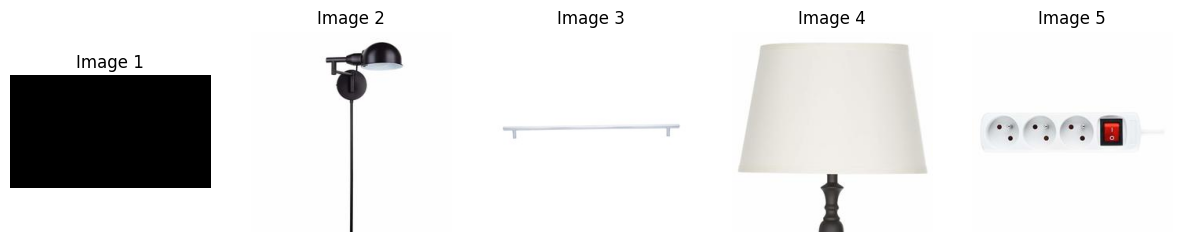

In [30]:
img_search = ImageSearch(engine, model)
img_search("man with a hat", 5, 5)

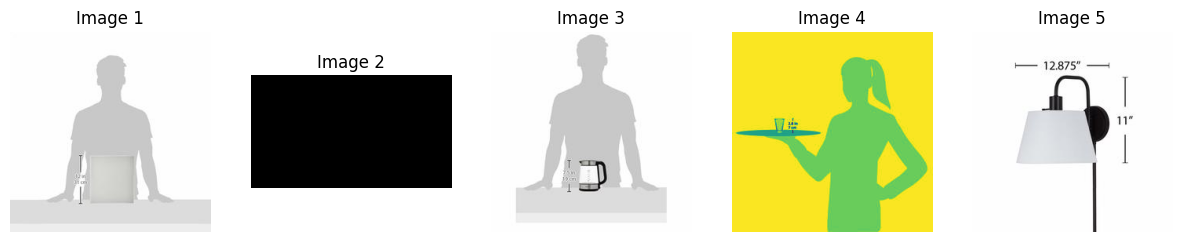

In [31]:
img_search = ImageSearch(engine, model)
img_search("man with a hat", 5, 50)

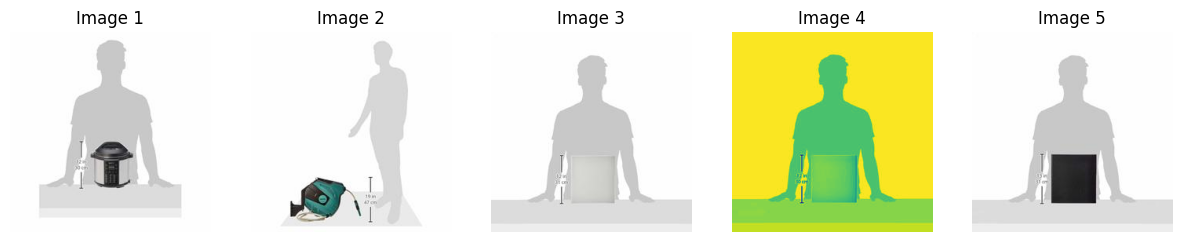

In [32]:
img_search = ImageSearch(engine, model)
img_search("man with a hat", 5)